In [1]:
using CairoMakie

In [185]:
R1 = 220
R2 = 220
R3 = 2200
R4 = 22000
R5 = 22000
R6 = 3300
BAT = 20
R7 = 100
R8 = 1000
R9 = 1000
R10 = 1800
C = 100e-9
L = R7*R9*C*R10/R8
C1 = 10e-9
C2 = 100e-9
R = 1800

function chua_params(p)
	(R1,R2,R3,R4,R5,R6,BAT) = p[1:7]
	E1 = R3/(R2+R3)*BAT
	E2 = R6/(R5+R6)*BAT
	m12 = -1/R6
	m02 = 1/R4
	m01 = 1/R1
	m11 = -1/R3
	m1 = m12 + m11 # -1/R6 - 1/R3
	m0 = m11 + m02 # -1/R3 + 1/R4
	mm1 = m01 + m02 # 1/R1 + 1/R4 
	Emax = max(E1,E2)
	Emin = min(E1, E2)

	return (E1,E2,m12,m02,m01,m11,m1,m0,mm1,Emax,Emin)
end

function g(x::Number,p::Any)
	
	(E1,E2,m12,m02,m01,m11,m1,m0,mm1,Emax,Emin) = chua_params(p)
	
	if abs.(x) .< Emin
		g = x * m1 
	elseif abs.(x) .< Emax
		g = x*m0
		if x>0
			g = g+ Emin*(m1-m0)
		else
			g = g+Emin*(m0-m1)
		end
	elseif abs.(x) >= Emax
		g = x*mm1
		if x>0 
			g = g+Emax*(m0-mm1) + Emin*(m1-m0)
		else
			g = g+Emax*(mm1-m0) + Emin*(m0-m1)
		end
	end
	return g
end

# function g(x::AbstractArray,p::Any)
# # function g(x::CuArray,p::Any)


# 	(E1,E2,m12,m02,m01,m11,m1,m0,mm1,Emax,Emin) = chua_params(p)
	
# 	mask_low = abs.(x) .< Emin
# 	mask_mid = (abs.(x) .>= Emin) .& (abs.(x) .< Emax)
# 	mask_high = abs.(x) .>= Emax

	
# 	result = similar(x, Float64)

# 	#Primera zona

# 	result[mask_low] = x[mask_low] * m1

# 	# Segunda zona:
# 	result[mask_mid] = x[mask_mid] * m0 
	
# 	pos_mask = x .> 0 
# 	mid_pos = mask_mid .& pos_mask
# 	mid_neg = mask_mid .& .!pos_mask
# 	result[mid_pos] .+= Emin*(m1-m0)
# 	result[mid_neg] .+= Emin*(m0-m1)

# 	#Tercera zona:
# 	result[mask_high] = x[mask_high] * mm1

# 	high_pos = mask_high .& pos_mask 
# 	high_neg = mask_high .& .!pos_mask 
# 	result[high_pos] .+= Emax * (m0 - mm1) + Emin * (m1 - m0)
# 	result[high_neg] .+= Emax * (mm1 - m0) + Emin * (m0 - m1)

# 	return result
# end

g (generic function with 1 method)

In [186]:
CairoMakie.activate!()

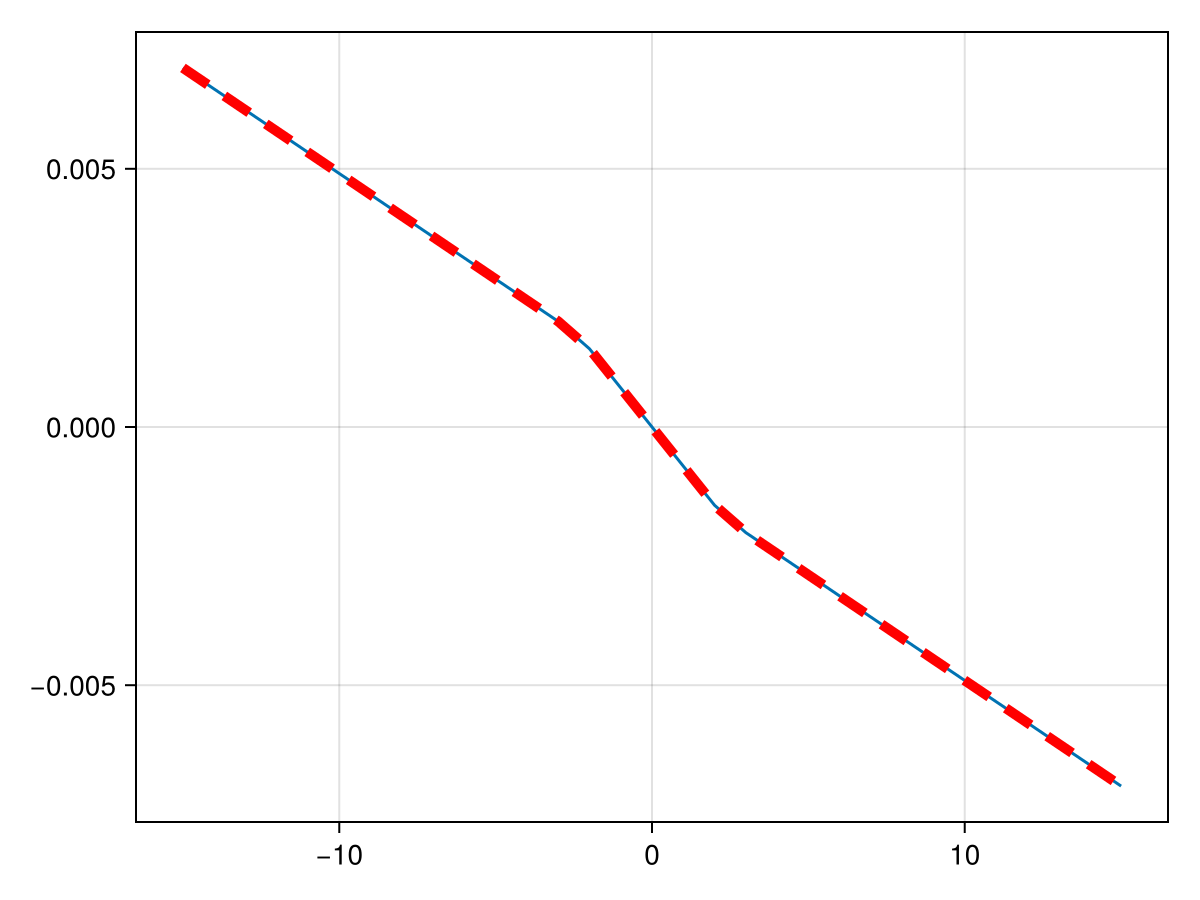

In [229]:
p0 = (R1,R2,R3,R4,R5,R6,18,R7,R8,R9,R10,C,L,C1,C2,1)
(E1,E2,m12,m02,m01,m11,m1,m0,mm1,Emax,Emin) = chua_params(p0)

x = -15:1:15

# lines(x,m1*x,color=:red)
lines(0,g(0,p0))
y = []
for x in x
    append!(y , g(x,p0))
# fig = lines(x,g(x,(R1,R2,R3,R4,R5,R6,18,R7,R8,R9,R10,C,L,C1,C2,10e3)))
end

y2 = (m0)*x + (m1 - m0).*(1/20 * log.(cosh.(20*(x.+Emin))) - 1/20 * log.(cosh.(20*(x.-Emin))))/2

lines(x,y)
lines!(x,y2,color=:red,linestyle = (:dash,2),linewidth=5)
current_figure()


In [161]:
m_afuerita = -4.090909090909
m_adentrito = -7.5757575757575
#con 20
#m_afuerita2 = m0
#m_adentrito2 = m1

#entonces para construir el coso seria a=m_afuerita. 2a-b= m_adentrito => b = 2m_afuerita- m_adentrito

y_dos = m_afuerita*x +(m_adentrito - m_afuerita).*(1/20 * log.(cosh.(20*(x.+1))) - 1/20 * log.(cosh.(20*(x.-1))))/2

y_tres = (m0)*x + (m1 - m0).*(1/20 * log.(cosh.(20*(x.+Emin))) - 1/20 * log.(cosh.(20*(x.-Emin))))/2

31-element Vector{Float64}:
  0.007045454545454545
  0.006636363636363636
  0.006227272727272727
  0.005818181818181819
  0.005409090909090909
  0.005000000000000001
  0.004590909090909092
  0.004181818181818182
  0.003772727272727273
  0.003363636363636364
  0.0029545454545454545
  0.002545454545454545
  0.0021363636349753757
  ⋮
 -0.0025454545454545456
 -0.002954545454545455
 -0.003363636363636364
 -0.003772727272727273
 -0.004181818181818182
 -0.004590909090909092
 -0.005000000000000001
 -0.0054090909090909085
 -0.005818181818181818
 -0.006227272727272727
 -0.006636363636363636
 -0.007045454545454545

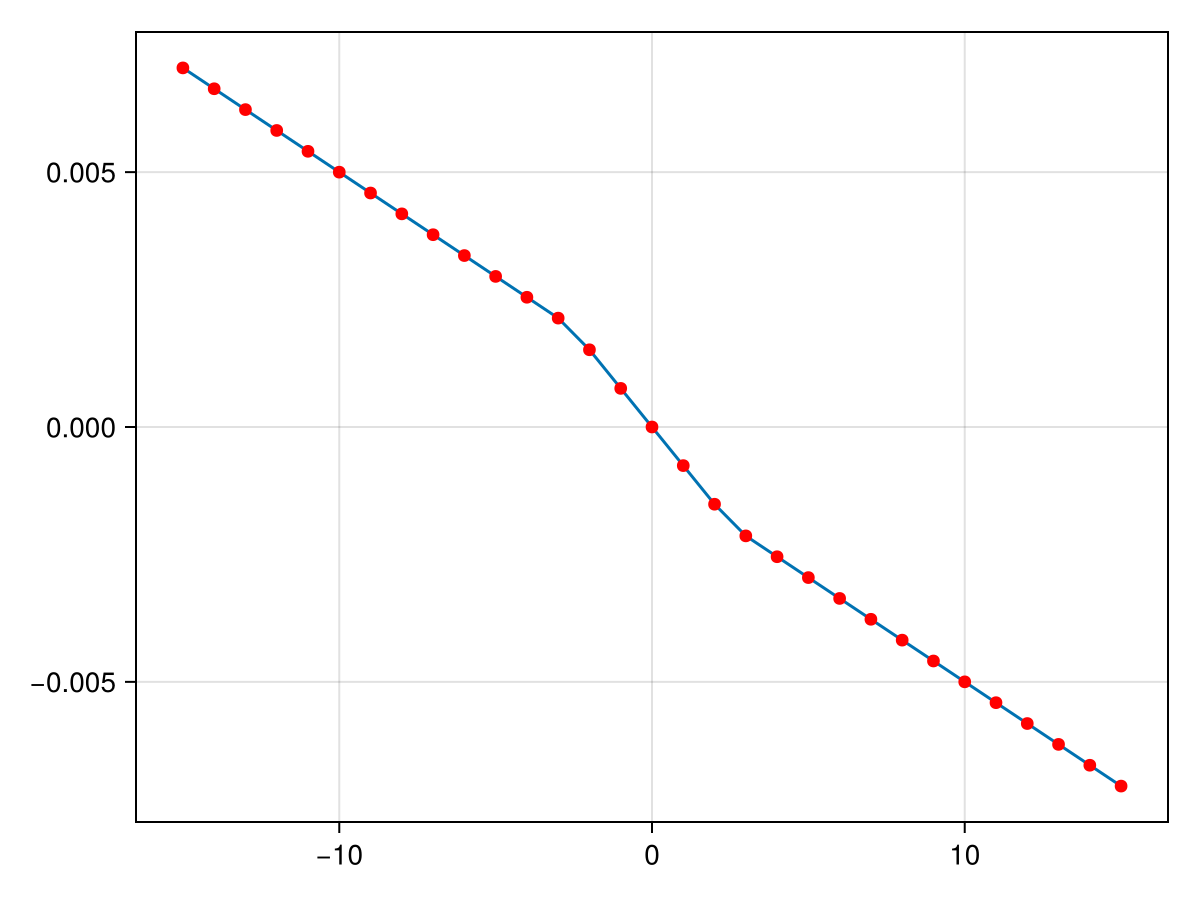

In [162]:
lines(x,y)
scatter!(x,y_tres,color=:red)
current_figure()

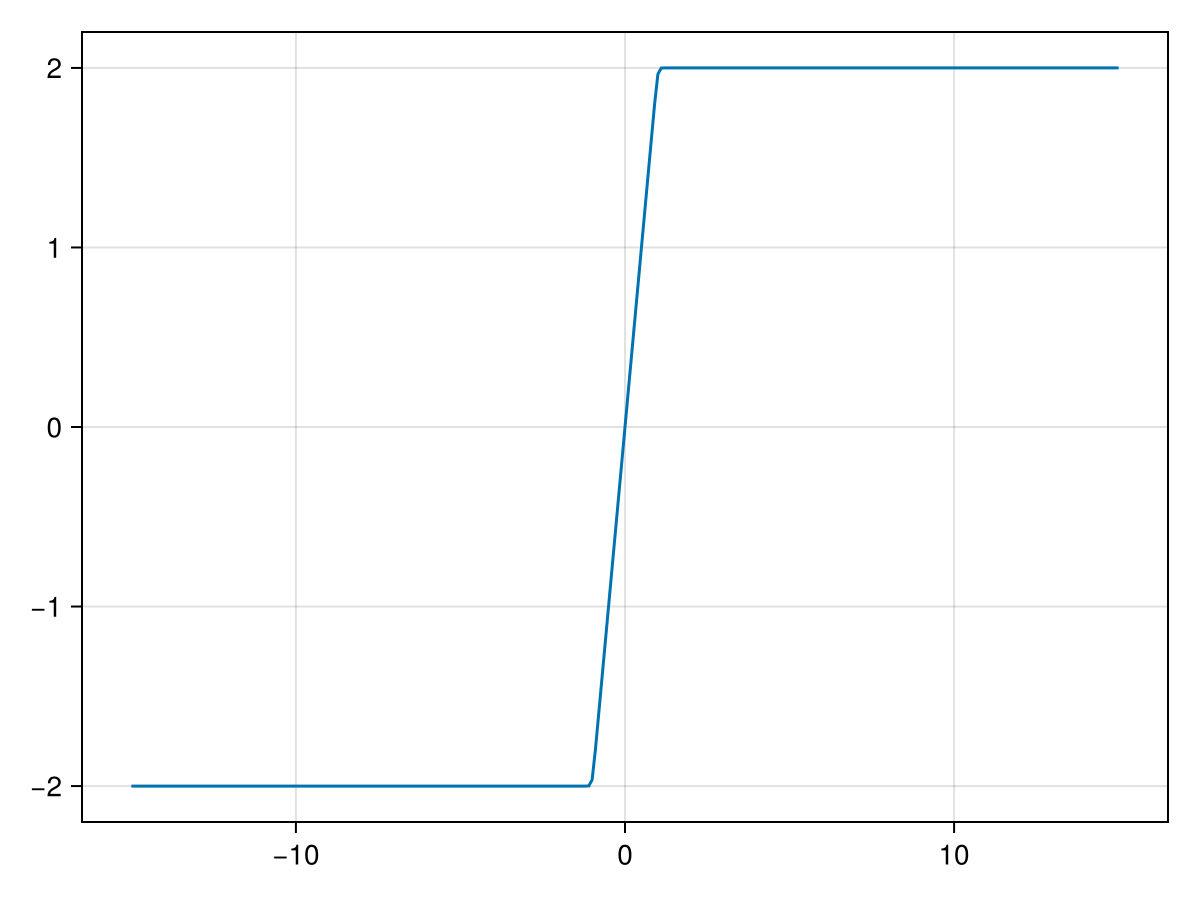

In [94]:
(1/20 * log.(cosh.(20*(x.+1))) - 1/20 * log.(cosh.(20*(x.-1))))

Finalmente tenemos que la función aproximada de Chua es:
$$(m0)x + (m1 - m0)(1/20 * log(cosh(20(x+Emin))) - 1/20 * log.(cosh(20(x-Emin))))/2$$ 


y de codigo ```(m0)*x + (m1 - m0).*(1/20 * log.(cosh.(20*(x.+Emin))) - 1/20 * log.(cosh.(20*(x.-Emin))))/2```

vamos a hacer todo para BAT = 18V. 

m1 = -1/R6 - 1/R3 = -1/3300 - 1/2200 = -1/1320

m0 = -1/R3 + 1/R4 = -1/2200 + 1/22000 = -9/22000

(m1-m0) = -1/R6 - 1/R4 = -23/66000

una g mas simplificada -1//22000*(9*x +23//(3*2)*(log.(cosh.(20*(x.+Emin))) - log.(cosh.(20*(x.-Emin))))/20)

Emin siempre es E2. 

E2 = R6/(R5+R6)*BAT = 3300/(22000+3300) * BAT = 3/23 * BAT

entonces la g final seria 

g = -1//22000*(9*x +23//(3*2)*(log.(cosh.(20*(x.+3//23 * BAT))) - log.(cosh.(20*(x.-3//23 * BAT))))/20)


R1 = 220

R2 = 220

R3 = 2200

R4 = 22000

R5 = 22000

R6 = 3300

BAT = 18

R7 = 100

R8 = 1000

R9 = 1000

R10 = 1800

C = 100e-9

L = R7*R9*C*R10/R8

C1 = 10e-9

C2 = 100e-9

R = 1800 - > variable 

In [251]:
L

0.018

In [248]:
y3 = -1//22000*(9*x +23//(3*2)*(log.(cosh.(20*(x.+3//23*18))) - log.(cosh.(20*(x.-3//23 * 18))))/20)

31-element Vector{Float64}:
  0.006954545454545454
  0.006545454545454545
  0.006136363636363636
  0.005727272727272727
  0.005318181818181818
  0.004909090909090909
  0.0045
  0.00409090909090909
  0.0036818181818181815
  0.0032727272727272726
  0.0028636363636363633
  0.0024545454545454545
  0.002045454545454505
  ⋮
 -0.0024545454545454545
 -0.0028636363636363633
 -0.0032727272727272726
 -0.0036818181818181815
 -0.00409090909090909
 -0.0045
 -0.004909090909090909
 -0.005318181818181818
 -0.005727272727272727
 -0.006136363636363636
 -0.006545454545454545
 -0.006954545454545454

In [ ]:
function chua_eq!(du,u,p,t)

    R = p 
    g = -1//22000*(9*u[1] +23//(3*2)*(log.(cosh.(20*(u[1].+3//23*18))) - log.(cosh.(20*(u[1].-3//23 * 18))))/20)

	du[1] = 1e8*(1/R * (u[2]-u[1]) - g )

	du[2] = 1e7*(1/R * (u[1]-u[2]) + u[3] )

	du[3] = -(500//9)*u[2]
    nothing
end